In [97]:
import numpy as np
import matplotlib.pyplot as plt


In [98]:
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    "text.latex.preamble": r"\usepackage{amsmath} \usepackage{amssymb}"
})

In [99]:
def compute_log_likelihood(M, alpha, data):

    # assume all are 1D

    M__ = M[:, None, None]
    alpha__ = alpha[None, :, None]
    data__ = data[None, None, :]

    log_likelihood = np.log(alpha__ + 1) - np.log(M__) + np.log(data__ / M__) * alpha__ + np.log(1e-100 + np.heaviside(M__ - data__, 0))
    log_likelihood = np.sum(log_likelihood, axis=-1)

    return log_likelihood

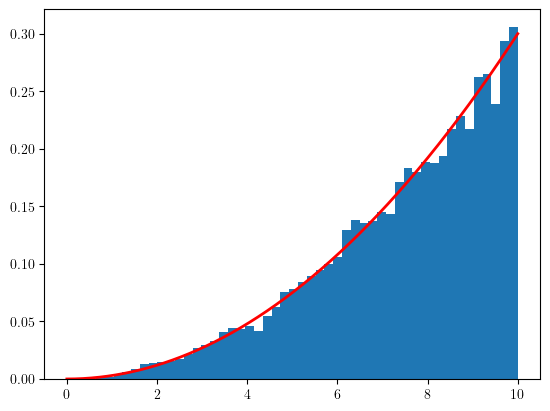

In [100]:
alpha_true = 2.0
M_true = 10.0

num_observations = 10000
data = np.random.uniform(0, 1, size=num_observations) ** (1 / (alpha_true + 1)) * M_true

x_vals = np.linspace(0, M_true, 1000)
y_vals = (alpha_true + 1) / M_true * (x_vals / M_true) ** alpha_true

plt.hist(data, bins=50, density=True)
plt.plot(x_vals, y_vals, color='red', linewidth=2)

In [101]:
M_vals = np.linspace(9.0, 12, 1000)
alpha_vals = np.linspace(0.1, 5, 500)

num_observations = [10, 30, 100, 400]
log_posterior = {}
for n in num_observations:
    log_posterior_nn = compute_log_likelihood(M_vals, alpha_vals, data[:n])
    log_posterior_nn -= np.max(log_posterior_nn)

    normalization = np.trapz(np.trapz(np.exp(log_posterior_nn), alpha_vals, axis=-1), M_vals, axis=-1)
    log_posterior[n] = log_posterior_nn - np.log(normalization)

/var/folders/6k/xt_kj55n7ds1y0cck0fxs9zh0000gp/T/ipykernel_79717/350367709.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  normalization = np.trapz(np.trapz(np.exp(log_posterior_nn), alpha_vals, axis=-1), M_vals, axis=-1)


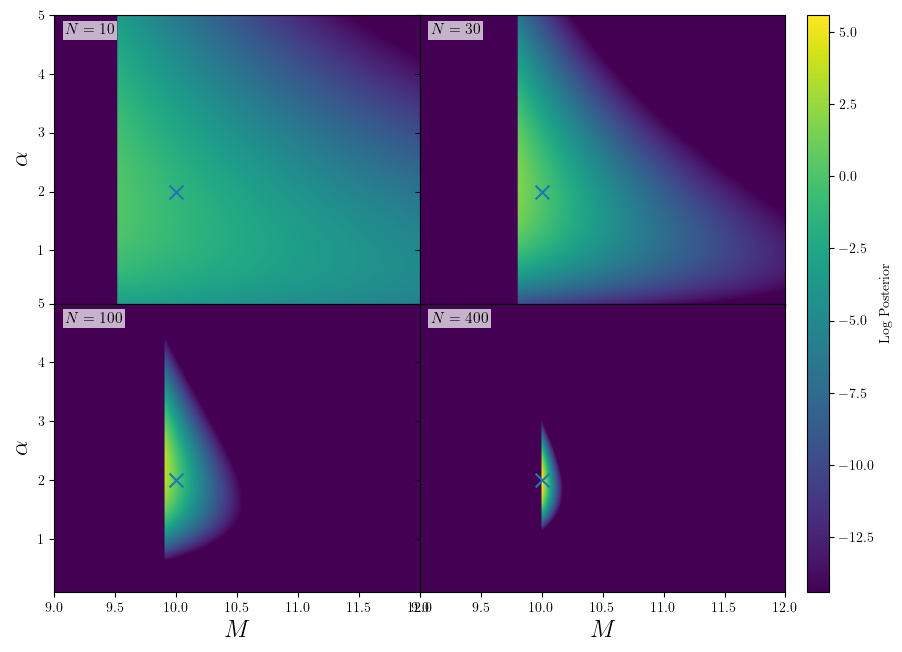

In [102]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

fig = plt.figure(figsize=(10, 7.5))
vmin = np.max([np.max(log_posterior[n]) for n in num_observations]) - 20
vmax = np.max([np.max(log_posterior[n]) for n in num_observations])

# Outer grid: [plots block | gap | colorbar]
outer = gridspec.GridSpec(
    1, 3,
    width_ratios=[1, 0.03, 0.03],  # middle column is a spacer
    wspace=0.0                     # keep outer tight; spacer creates the gap
)

# Inner grid for the 2x2 plots: panels touch
inner = gridspec.GridSpecFromSubplotSpec(
    2, 2,
    subplot_spec=outer[0, 0],
    wspace=0.0,
    hspace=0.0
)

axs = np.empty((2, 2), dtype=object)

for i, n in enumerate(num_observations):
    row = i // 2
    col = i % 2
    ax = fig.add_subplot(inner[row, col])
    axs[row, col] = ax

    im = ax.imshow(
        log_posterior[n].T,
        extent=(M_vals[0], M_vals[-1], alpha_vals[0], alpha_vals[-1]),
        aspect='auto',
        origin='lower',
        vmin=vmin,
        vmax=vmax
    )

    ax.scatter(M_true, alpha_true, marker='x', s=100)

    # N label inside panel
    ax.text(
        0.03, 0.97, rf'$N={n}$',
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=11,
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
    )

    # Clean inner tick labels
    if row == 0:
        ax.tick_params(labelbottom=False)
    if col == 1:
        ax.tick_params(labelleft=False)

    # Only outer labels
    if row == 1:
        ax.set_xlabel('$M$', fontsize=18)
    if col == 0:
        ax.set_ylabel('$\\alpha$', fontsize=18)

# Colorbar axis (separate outer column)
cax = fig.add_subplot(outer[0, 2])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Log Posterior')

plt.savefig('plots/example_power_law_distribution_varying_N.pdf', bbox_inches='tight')
plt.show()